#  Human Activity Recognition with a Hidden Markov Model

This notebook uses the Sensor Logger app to record data from the smartphone's accelerometer and gyroscope to construct a Hidden Markov model (HMM) from scratch in NumPy to infer four activities (standing, walking, jumping, still).

**Pipeline:** data collection, cleaning and resampling, windowing, feature extraction and Z-score normalisation, Baum-Welch training, Viterbi decoding and evaluation on unseen recordings.

**Key settings:** the phone recorded at about 100 Hz and every recording is resampled to 60 Hz. Features are computed on 2-second windows (120 samples) with 50% overlap.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


BASE     = "/content/drive/MyDrive/HMM"
ZIP_DIR  = f"{BASE}/ZIP"
PROC_DIR = f"{BASE}/processed"
FEAT_DIR = f"{BASE}/features"
os.makedirs(PROC_DIR, exist_ok=True); os.makedirs(FEAT_DIR, exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]
FS         = 60
WIN_SEC    = 2.0
OVERLAP    = 0.5
USE_LOG    = True
# -------------------------------------------------------------------------
WIN  = int(WIN_SEC * FS)
STEP = int(WIN * (1 - OVERLAP))
print("Window =", WIN, "samples, step =", STEP, "samples")

Mounted at /content/drive
Window = 120 samples, step = 60 samples


## 1. Data collection

All recordings are from 1 phone and are exported as zip files from Sensor Logger. There are 60 training recordings in the folder (15 for each activity), and 2 test recordings (test_01, test_02) that the model is never training on. The cell below ensures that all the files are included.

In [ ]:
zips = sorted(glob.glob(os.path.join(ZIP_DIR, "*.zip")))
print("Zip files found:", len(zips))
for z in zips:
    print(" ", os.path.basename(z))

Zip files found: 62
  Test_01.zip
  Test_02.zip
  carla_jumping_01-2026-10-25_07-26-58.zip
  carla_jumping_02-2026-10-25_17-00-08.zip
  carla_jumping_03-2026-10-25_17-01-00.zip
  carla_jumping_04-2026-10-25_17-01-37.zip
  carla_jumping_05-2026-10-25_17-01-57.zip
  carla_jumping_06-2026-10-25_17-02-11.zip
  carla_jumping_07-2026-10-25_17-02-29.zip
  carla_jumping_08-2026-10-25_17-09-28.zip
  carla_jumping_09-2026-10-25_17-09-38.zip
  carla_jumping_10-2026-10-25_17-09-58.zip
  carla_jumping_11-2026-10-25_17-10-15.zip
  carla_jumping_12-2026-10-25_17-12-00.zip
  carla_jumping_13-2026-10-25_17-12-18.zip
  carla_jumping_14-2026-10-25_17-12-29.zip
  carla_jumping_15-2026-10-25_17-12-39.zip
  carla_standing_01-2026-10-25_07-25-49.zip
  carla_standing_02-2026-10-25_17-27-51.zip
  carla_standing_03-2026-10-25_17-27-43.zip
  carla_standing_04-2026-10-25_17-27-30.zip
  carla_standing_05-2026-10-25_17-27-22.zip
  carla_standing_06-2026-10-25_17-27-14.zip
  carla_standing_07-2026-10-25_17-27-03.zip

## 2. Clean, resample and clips

Its slightly different that the accelerometer and the gyroscope in Sensor Logger are not in sync. This step:
- interpolates both sensors to the same, uniformly-spaced, 60 Hz time grid,
- saves short recordings (5-10 seconds) as single clips and trims and cuts longer recordings,
- preserves the test recordings complete to be able to decode each separately,
- saves the clips as a collection of labelled CSV files

At the end there is a table that lists the raw sampling rate, length and number of clips/segments for each file.


In [ ]:
CLIP_SEC = 5
TRIM_SEC = 3
LONG_SEC = 12

def get_label(name):
    n = name.lower()
    if n.startswith("test"):
        return "test"
    for a in ACTIVITIES:
        if a in n:
            return a
    return None

def load_zip(path):
    with zipfile.ZipFile(path) as z:
        acc = pd.read_csv(z.open("Accelerometer.csv"))
        gyr = pd.read_csv(z.open("Gyroscope.csv"))
    return acc, gyr

def resample(acc, gyr, hz):
    """Put both sensors on one shared, evenly spaced time grid."""
    t0 = max(acc.seconds_elapsed.min(), gyr.seconds_elapsed.min())
    t1 = min(acc.seconds_elapsed.max(), gyr.seconds_elapsed.max())
    t = np.arange(t0, t1, 1.0 / hz)
    out = pd.DataFrame({"timestamp": t - t0})
    for ax in ["x", "y", "z"]:
        out["acc_" + ax] = np.interp(t, acc.seconds_elapsed, acc[ax])
        out["gyro_" + ax] = np.interp(t, gyr.seconds_elapsed, gyr[ax])
    return out

def cut_clips(df, hz, clip_sec):
    n = int(clip_sec * hz)
    clips = []
    for i in range(len(df) // n):
        c = df.iloc[i * n:(i + 1) * n].copy()
        c["timestamp"] = c["timestamp"] - c["timestamp"].iloc[0]
        clips.append(c)
    return clips

rows, seen = [], set()
for zp in sorted(glob.glob(os.path.join(ZIP_DIR, "*.zip"))):
    name = os.path.splitext(os.path.basename(zp))[0].split("-20")[0].lower()   # e.g. carla_still_15, test_01
    if name in seen:
        print("DUPLICATE skipped:", os.path.basename(zp)); continue
    label = get_label(name)
    if label is None:
        print("SKIPPED (no activity in name):", name); continue
    seen.add(name)
    acc, gyr = load_zip(zp)
    raw_hz = round(1 / np.median(np.diff(acc.seconds_elapsed)), 1)
    df = resample(acc, gyr, FS)
    dur = df.timestamp.iloc[-1]
    folder = os.path.join(PROC_DIR, label); os.makedirs(folder, exist_ok=True)

    if label == "test":
        clips = [df]
    elif dur > LONG_SEC:
        trimmed = df[(df.timestamp >= TRIM_SEC) & (df.timestamp <= dur - TRIM_SEC)]
        clips = cut_clips(trimmed.reset_index(drop=True), FS, CLIP_SEC)
    else:
        clips = [df]

    for i, c in enumerate(clips, 1):
        fn = f"{name}_clip{i:02d}.csv" if len(clips) > 1 else f"{name}.csv"
        c.to_csv(os.path.join(folder, fn), index=False)
    rows.append(dict(file=name, label=label, raw_hz=raw_hz, seconds=round(dur, 1), clips=len(clips)))

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
print("\nClips and total seconds per activity:")
print(summary.groupby("label").agg(clips=("clips", "sum"), seconds=("seconds", "sum")))

             file    label  raw_hz  seconds  clips
          test_01     test   100.2     61.5      1
          test_02     test   100.2     61.3      1
 carla_jumping_01  jumping   100.2      7.1      1
 carla_jumping_02  jumping   100.2      6.5      1
 carla_jumping_03  jumping   100.2      6.1      1
 carla_jumping_04  jumping   100.2      6.9      1
 carla_jumping_05  jumping   100.2      7.1      1
 carla_jumping_06  jumping   100.2      7.1      1
 carla_jumping_07  jumping   100.2      6.8      1
 carla_jumping_08  jumping   100.2      7.1      1
 carla_jumping_09  jumping   100.2      7.3      1
 carla_jumping_10  jumping   100.2      6.9      1
 carla_jumping_11  jumping   100.2      7.1      1
 carla_jumping_12  jumping   100.2      8.6      1
 carla_jumping_13  jumping   100.2      7.9      1
 carla_jumping_14  jumping   100.2      8.4      1
 carla_jumping_15  jumping   100.2      6.3      1
carla_standing_01 standing   100.2      7.3      1
carla_standing_02 standing   10

 ## 3. Visualising the data

Magnitude of acceleration vs. time for one clip each activity, and the FFT Spectrum for each clip. Walking and jumping clearly have repeating patterns, standing and still have almost flat patterns which in turn anticipate the main difficulty faced by the model.




Clips loaded: {'standing': 15, 'walking': 15, 'jumping': 15, 'still': 15}


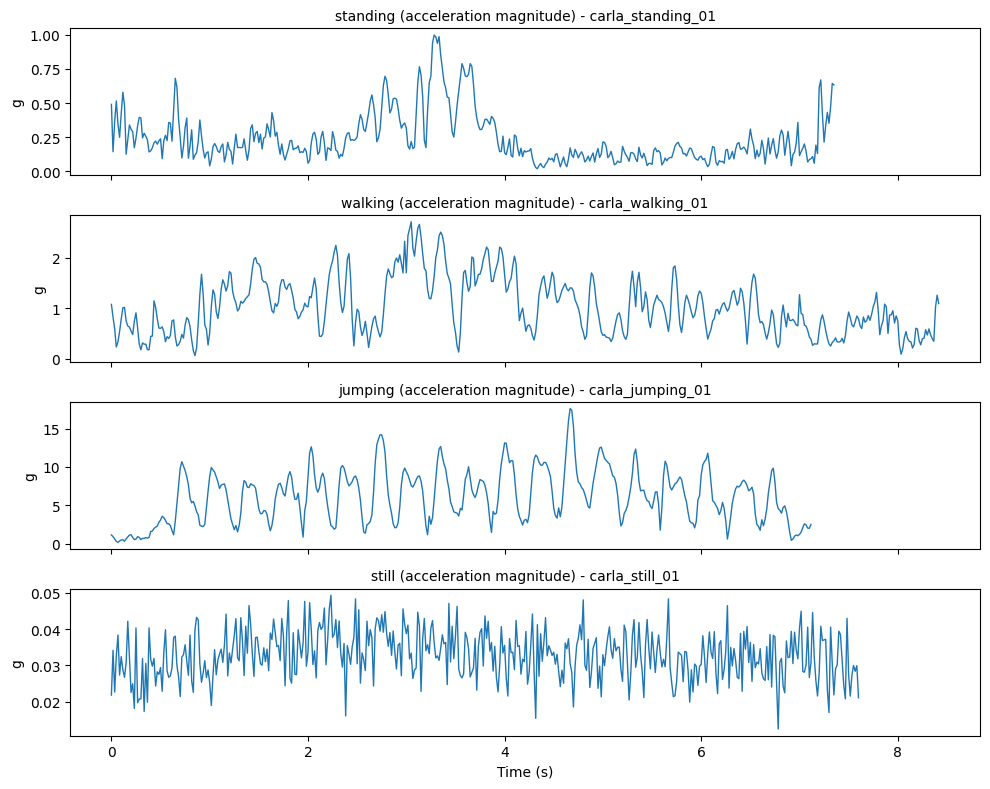

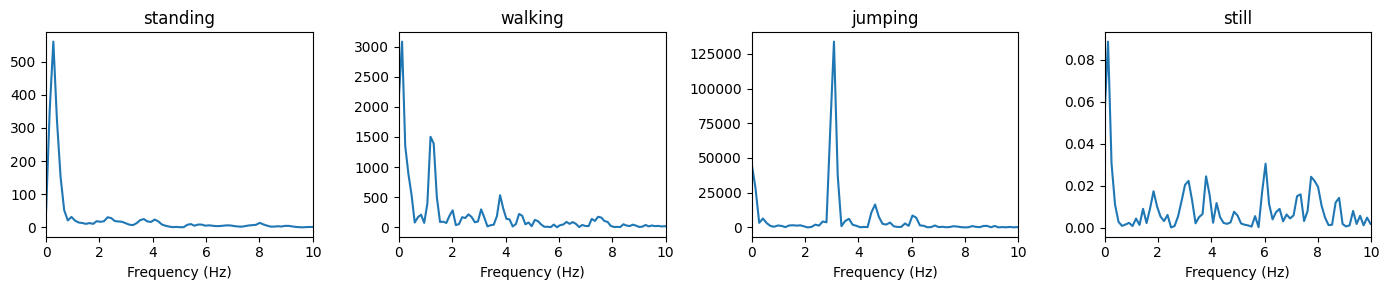

In [ ]:
def load_clips(proc_dir):
    clips = []
    for lab in ACTIVITIES:
        for f in sorted(glob.glob(os.path.join(proc_dir, lab, "*.csv"))):
            clips.append((os.path.basename(f).replace(".csv", ""), lab, pd.read_csv(f)))
    return clips

def spectrum(sig, fs):
    sig = sig - sig.mean()
    p = np.abs(np.fft.rfft(sig * np.hanning(len(sig)))) ** 2
    return np.fft.rfftfreq(len(sig), 1 / fs), p

clips = load_clips(PROC_DIR)
print("Clips loaded:", {a: sum(1 for c in clips if c[1] == a) for a in ACTIVITIES})

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, a in zip(axes, ACTIVITIES):
    name, lab, df = next(c for c in clips if c[1] == a)
    m = np.linalg.norm(df[["acc_x", "acc_y", "acc_z"]].values, axis=1)
    ax.plot(df.timestamp, m, lw=1)
    ax.set_title(f"{a} (acceleration magnitude) - {name}", fontsize=10); ax.set_ylabel("g")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/raw_signals.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, a in zip(axes, ACTIVITIES):
    name, lab, df = next(c for c in clips if c[1] == a)
    m = np.linalg.norm(df[["acc_x", "acc_y", "acc_z"]].values, axis=1)
    fr, p = spectrum(m, FS)
    ax.plot(fr, p); ax.set_xlim(0, 10); ax.set_title(a); ax.set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/fft_spectra.png", dpi=150); plt.show()

## 4. Remove non-essential data features and normalize data.
There are 16 features, 8 from the accelerometer and 8 from the gyroscope, calculated for each 2-second window (120 samples @ 60 Hz).

In time domain: mean, RMS, x-y axis correlation and standard deviation. These are a measure of degrees of strength and variability.
In the Frequency domain (FFT): dominant frequency, spectral energy and spectral entropy. These relate to the rhythmic characteristics, e.g. the rate of steps in walking.

The amplitude features are of different orders of magnitude in the different activities, therefore, they are log transformed, and then **Z-score normalised** with the mean and standard deviation of the training data. The same values used are reused on the test data to prevent leakage.

Windows per activity:
 label
jumping     86
walking     84
standing    78
still       78
Name: count, dtype: int64
Features: 16 | log-transformed: ['acc_mean', 'acc_std', 'acc_rms', 'acc_sma', 'gyro_mean', 'gyro_std', 'gyro_rms', 'gyro_sma']


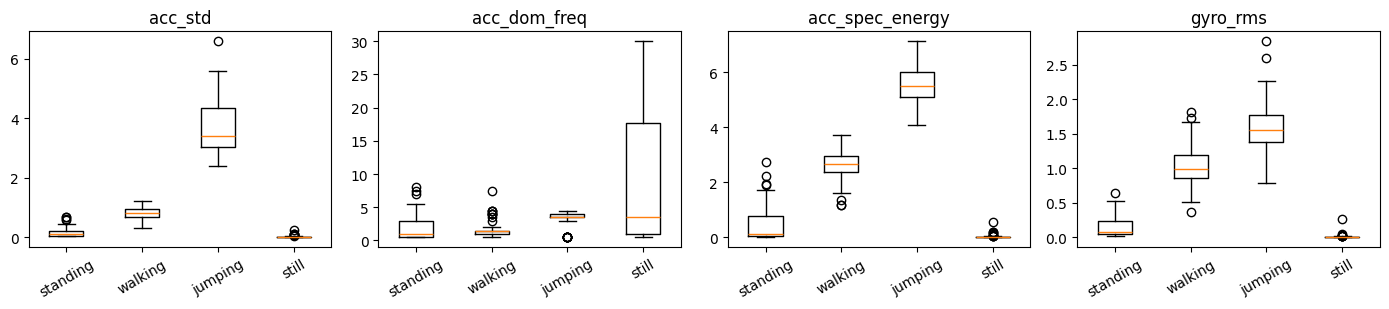

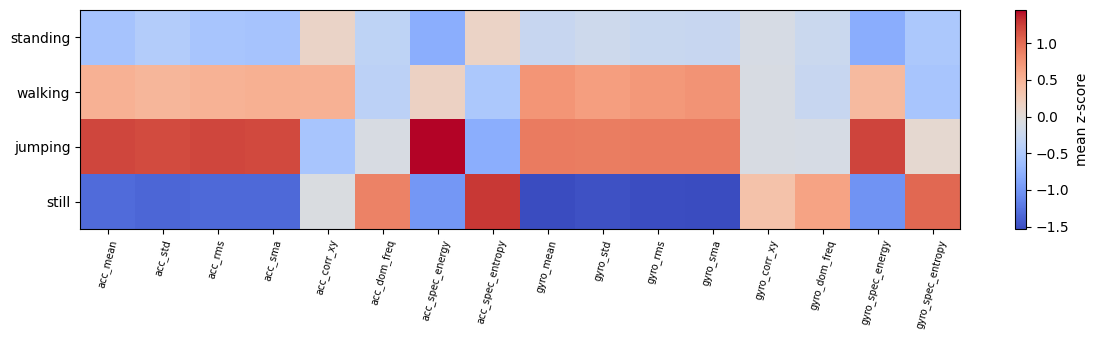

In [ ]:
def sensor_features(w, prefix, fs):
    xyz = w[[f"{prefix}_x", f"{prefix}_y", f"{prefix}_z"]].values
    m = np.linalg.norm(xyz, axis=1)
    freqs, p = spectrum(m, fs)
    p_nz, f_nz = p[1:], freqs[1:]
    total = p_nz.sum() + 1e-12
    pn = p_nz / total
    corr = np.nan_to_num(np.corrcoef(xyz.T))
    return {
        f"{prefix}_mean": m.mean(),
        f"{prefix}_std": m.std(),
        f"{prefix}_rms": np.sqrt(np.mean(m ** 2)),
        f"{prefix}_sma": np.mean(np.abs(xyz).sum(axis=1)),
        f"{prefix}_corr_xy": corr[0, 1],
        f"{prefix}_dom_freq": f_nz[np.argmax(p_nz)],
        f"{prefix}_spec_energy": np.log1p(total / len(m)),
        f"{prefix}_spec_entropy": -(pn * np.log2(pn + 1e-12)).sum()
    }

def extract_windows(df, fs=FS):
    """Returns a list of feature dicts (one per window) and the window start times."""
    feats, starts = [], []
    for s in range(0, len(df) - WIN + 1, STEP):
        w = df.iloc[s:s + WIN]
        row = {}
        row.update(sensor_features(w, "acc", fs))
        row.update(sensor_features(w, "gyro", fs))
        feats.append(row); starts.append(s / fs)
    return feats, starts

rows = []
for name, lab, df in clips:
    feats, _ = extract_windows(df)
    for k, f in enumerate(feats):
        f.update(clip=name, label=lab, win=k)
        rows.append(f)
feat = pd.DataFrame(rows)
FEATURE_COLS = [c for c in feat.columns if c not in ("clip", "label", "win")]
LOG_COLS = [c for c in FEATURE_COLS if c.endswith(("_mean", "_std", "_rms", "_sma"))] if USE_LOG else []
EPS = 1e-4

def transform(df_feat):
    """Log (optional) on amplitude features. The same function is used for the test data."""
    out = df_feat.copy()
    if LOG_COLS:
        out[LOG_COLS] = np.log(out[LOG_COLS] + EPS)
    return out

logged = transform(feat)
mu = logged[FEATURE_COLS].mean()
sd = logged[FEATURE_COLS].std().replace(0, 1)
feat_z = logged.copy()
feat_z[FEATURE_COLS] = (logged[FEATURE_COLS] - mu) / sd

feat.to_csv(f"{FEAT_DIR}/features_raw.csv", index=False)
feat_z.to_csv(f"{FEAT_DIR}/features_zscore.csv", index=False)
mu.to_csv(f"{FEAT_DIR}/zscore_mean.csv"); sd.to_csv(f"{FEAT_DIR}/zscore_std.csv")
print("Windows per activity:\n", feat.label.value_counts())
print("Features:", len(FEATURE_COLS), "| log-transformed:", LOG_COLS)

key = ["acc_std", "acc_dom_freq", "acc_spec_energy", "gyro_rms"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, k in zip(axes, key):
    ax.boxplot([feat[feat.label == a][k] for a in ACTIVITIES])
    ax.set_xticklabels(ACTIVITIES, rotation=30); ax.set_title(k)
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/feature_boxplots.png", dpi=150); plt.show()

means = feat_z.groupby("label")[FEATURE_COLS].mean().loc[ACTIVITIES]
plt.figure(figsize=(12, 3.5))
plt.imshow(means.values, aspect="auto", cmap="coolwarm")
plt.xticks(range(len(FEATURE_COLS)), FEATURE_COLS, rotation=75, fontsize=7)
plt.yticks(range(4), ACTIVITIES); plt.colorbar(label="mean z-score")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/feature_heatmap.png", dpi=150); plt.show()

## 5. A basic implementation of HMM: The Baum-Welch and the Viterbi implementation.


**Model components**
- State z that is hidden: Stand, Walk, Jump, Still
Observations X: 16 dimensional normalised feature vector for each window.
- Probabilities for emission: B = 1 digaussian per state
- Transition probabilities A and initial probabilities π: learned from the data

Baum-Welch (EM) algorithms learn A, B and π from the feature sequences and terminate when the relative change of the total log-likelihood is below a tolerance level. Viterbi decodes one of the most likely activity sequences for a recording. The quality of the decoding affects the computation of sensitivity, specificity and accuracy in this report, which are computed using the Viterbi-decoded states. Per-window posterior decoding is not used, as it requires many independent paths that do not consider the path probabilities.

In [ ]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    s = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return s.squeeze(axis) if axis is not None else s.item()

class GaussianHMM:
    """HMM with diagonal-Gaussian emissions.
    pi: initial probs (K,)   A: transitions (K,K)   mu, var: emission params (K,D)"""

    def __init__(self, n_states, n_features, var_floor=1e-2):
        self.K, self.D, self.var_floor = n_states, n_features, var_floor

    def init_supervised(self, seqs, labels, smooth=1.0):
        """Start from the labelled windows so state k always means activity k."""
        K = self.K
        X = np.vstack(seqs); y = np.concatenate(labels)
        self.mu = np.array([X[y == k].mean(0) for k in range(K)])
        self.var = np.array([X[y == k].var(0) for k in range(K)]) + self.var_floor
        first = np.array([l[0] for l in labels])
        self.pi = (np.bincount(first, minlength=K) + smooth) / (len(first) + K * smooth)
        counts = np.zeros((K, K))
        for l in labels:
            for a, b in zip(l[:-1], l[1:]):
                counts[a, b] += 1
        self.A = (counts + smooth) / (counts + smooth).sum(1, keepdims=True)
        return self

    def log_emission(self, X):
        """log B[t,k] = log p(x_t | state k)"""
        diff = X[:, None, :] - self.mu[None, :, :]
        return -0.5 * np.sum(np.log(2 * np.pi * self.var)[None] + diff ** 2 / self.var[None], axis=2)

    def forward(self, logB):
        T = logB.shape[0]
        la = np.zeros((T, self.K)); logA = np.log(self.A)
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        return la, logsumexp(la[-1])

    def backward(self, logB):
        T = logB.shape[0]
        lb = np.zeros((T, self.K)); logA = np.log(self.A)
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        return lb

    def baum_welch(self, seqs, max_iter=200, tol=1e-4, a_prior=1.0, verbose=True):
        """EM training. Stops when the relative change in total log-likelihood < tol."""
        K, D = self.K, self.D
        history = []
        for it in range(max_iter):
            pi_n = np.zeros(K); A_n = np.zeros((K, K))
            g_sum = np.zeros(K); gx = np.zeros((K, D)); gxx = np.zeros((K, D))
            total_ll = 0.0
            logA = np.log(self.A)
            for X in seqs:
                logB = self.log_emission(X)
                la, ll = self.forward(logB); lb = self.backward(logB)
                total_ll += ll
                gamma = np.exp(la + lb - ll)
                pi_n += gamma[0]; g_sum += gamma.sum(0)
                gx += gamma.T @ X; gxx += gamma.T @ (X ** 2)
                for t in range(len(X) - 1):
                    xi = la[t][:, None] + logA + (logB[t + 1] + lb[t + 1])[None, :] - ll
                    A_n += np.exp(xi)
            history.append(total_ll)
            self.pi = (pi_n + 1e-8) / (pi_n + 1e-8).sum()
            self.A = (A_n + a_prior) / (A_n + a_prior).sum(1, keepdims=True)
            self.mu = gx / g_sum[:, None]
            self.var = np.maximum(gxx / g_sum[:, None] - self.mu ** 2, 0) + self.var_floor
            if it > 0 and abs(history[-1] - history[-2]) < tol * abs(history[-2]):
                if verbose: print(f"Converged at iteration {it + 1} (relative change < {tol})")
                break
            if verbose and it % 5 == 0: print(f"iter {it + 1:3d}  log-likelihood = {total_ll:.2f}")
        else:
            if verbose: print("Reached max_iter without meeting the tolerance")
        self.history = history
        return history

    def viterbi(self, X):
        """Most likely hidden-state path for one observation sequence."""
        T = X.shape[0]; logB = self.log_emission(X); logA = np.log(self.A)
        delta = np.zeros((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            psi[t] = scores.argmax(0)
            delta[t] = scores.max(0) + logB[t]
        path = np.zeros(T, dtype=int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

print("HMM class defined.")

HMM class defined.


## 6. Training

Three clips per activity are initially retained as a quick check that the clips is correct. The final model is then trained with all 60 training clips. The parameters are initialized by the labelled windows: the state k is set to the activity k, followed by the refinement with the Baum-Welch.


In [ ]:
lab2id = {a: i for i, a in enumerate(ACTIVITIES)}

def make_sequences(df):
    seqs, labs, names = [], [], []
    for clip, g in df.groupby("clip", sort=True):
        g = g.sort_values("win")
        seqs.append(g[FEATURE_COLS].values)
        labs.append(g["label"].map(lab2id).values)
        names.append(clip)
    return seqs, labs, names

seqs, labs, names = make_sequences(feat_z)
print(f"{len(seqs)} sequences, {sum(len(s) for s in seqs)} windows, {len(FEATURE_COLS)} features")


rng = np.random.default_rng(42)
val_idx = []
for a in ACTIVITIES:
    idx = [i for i, l in enumerate(labs) if l[0] == lab2id[a]]
    val_idx += list(rng.choice(idx, 3, replace=False))
tr_idx = [i for i in range(len(seqs)) if i not in val_idx]

hmm = GaussianHMM(len(ACTIVITIES), len(FEATURE_COLS))
hmm.init_supervised([seqs[i] for i in tr_idx], [labs[i] for i in tr_idx])
hmm.baum_welch([seqs[i] for i in tr_idx])
pred = np.concatenate([hmm.viterbi(seqs[i])[0] for i in val_idx])
true = np.concatenate([labs[i] for i in val_idx])
print(f"\nValidation window accuracy (held-out clips): {(pred == true).mean():.3f}")


final = GaussianHMM(len(ACTIVITIES), len(FEATURE_COLS))
final.init_supervised(seqs, labs)
hist = final.baum_welch(seqs)
np.savez(f"{FEAT_DIR}/hmm_params.npz", pi=final.pi, A=final.A, mu=final.mu, var=final.var)

print("\nTransition matrix A:\n", pd.DataFrame(final.A, index=ACTIVITIES, columns=ACTIVITIES).round(3))
print("\nInitial probabilities pi:", dict(zip(ACTIVITIES, final.pi.round(3))))

60 sequences, 326 windows, 16 features
iter   1  log-likelihood = -893.60
iter   6  log-likelihood = -806.61
Converged at iteration 7 (relative change < 0.0001)

Validation window accuracy (held-out clips): 0.848
iter   1  log-likelihood = -1292.60
iter   6  log-likelihood = -1103.14
Converged at iteration 8 (relative change < 0.0001)

Transition matrix A:
           standing  walking  jumping  still
standing     0.845    0.056    0.014  0.085
walking      0.048    0.868    0.072  0.012
jumping      0.014    0.014    0.957  0.014
still        0.017    0.017    0.017  0.948

Initial probabilities pi: {'standing': np.float64(0.317), 'walking': np.float64(0.35), 'jumping': np.float64(0.167), 'still': np.float64(0.167)}


## 7. Transition, emission and convergence plots

- **Transition matrix A:** probability of moving from each activity to each other activity.
- **Emission means B:** the average normalised feature pattern each state expects.
- **Convergence:** log-likelihood per Baum-Welch iteration.
- **Decoded sequence:** Viterbi output compared with the true activity on held-out training clips.

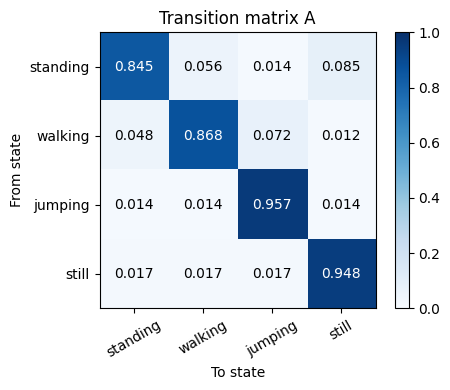

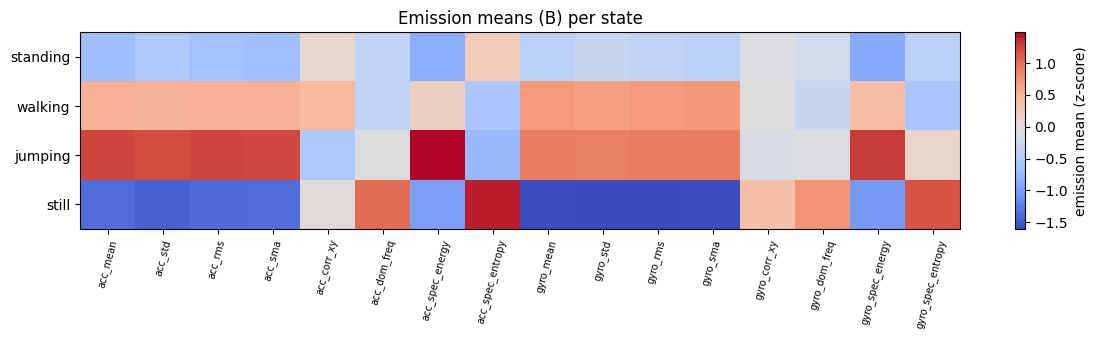

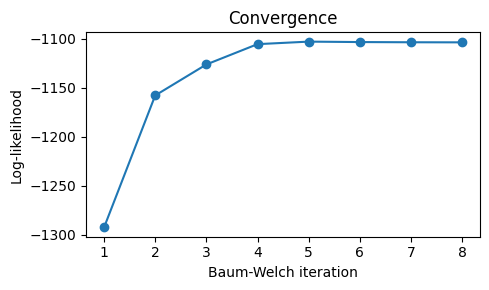

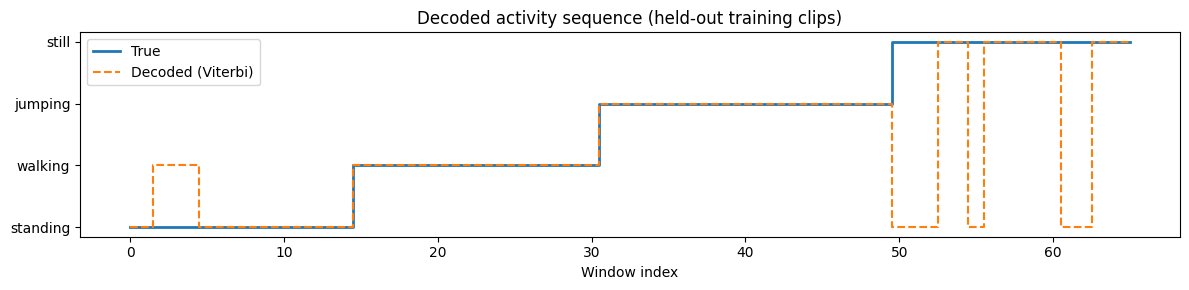

In [ ]:
plt.figure(figsize=(5, 4))
plt.imshow(final.A, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{final.A[i, j]:.3f}", ha="center", va="center",
                 color="white" if final.A[i, j] > 0.5 else "black")
plt.xticks(range(4), ACTIVITIES, rotation=30); plt.yticks(range(4), ACTIVITIES)
plt.xlabel("To state"); plt.ylabel("From state"); plt.title("Transition matrix A")
plt.colorbar(); plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/transition_heatmap.png", dpi=150); plt.show()

plt.figure(figsize=(12, 3.5))
plt.imshow(final.mu, aspect="auto", cmap="coolwarm")
plt.xticks(range(len(FEATURE_COLS)), FEATURE_COLS, rotation=75, fontsize=7)
plt.yticks(range(4), ACTIVITIES); plt.colorbar(label="emission mean (z-score)")
plt.title("Emission means (B) per state"); plt.tight_layout()
plt.savefig(f"{FEAT_DIR}/emission_heatmap.png", dpi=150); plt.show()

plt.figure(figsize=(5, 3)); plt.plot(range(1, len(hist) + 1), hist, marker="o")
plt.xlabel("Baum-Welch iteration"); plt.ylabel("Log-likelihood"); plt.title("Convergence")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/bw_convergence.png", dpi=150); plt.show()

vp = np.concatenate([final.viterbi(seqs[i])[0] for i in val_idx])
plt.figure(figsize=(12, 3))
plt.step(range(len(true)), true, where="mid", label="True", lw=2)
plt.step(range(len(vp)), vp, where="mid", label="Decoded (Viterbi)", ls="--")
plt.yticks(range(4), ACTIVITIES); plt.xlabel("Window index"); plt.legend()
plt.title("Decoded activity sequence (held-out training clips)"); plt.tight_layout()
plt.savefig(f"{FEAT_DIR}/decoded_validation.png", dpi=150); plt.show()

## 8. Which activities get confused?

Confusion counts on the held-out and all training clips, plus the raw feature values for standing versus still, the activity pair with the most similar signals.

In [ ]:
def confusion(model, idx):
    C = np.zeros((4, 4), int)
    for i in idx:
        p, _ = model.viterbi(seqs[i])
        for t, pp in zip(labs[i], p):
            C[t, pp] += 1
    return C

lbl = lambda p: [f"{p} {a}" for a in ACTIVITIES]
print("Held-out clips (model trained without them):")
print(pd.DataFrame(confusion(hmm, val_idx), index=lbl("true"), columns=lbl("pred")))
print("\nAll training clips (final model):")
print(pd.DataFrame(confusion(final, range(len(seqs))), index=lbl("true"), columns=lbl("pred")))
cols = ["acc_std", "acc_rms", "gyro_std", "gyro_rms", "acc_spec_energy", "acc_dom_freq"]
print("\nStanding vs still, raw feature values:")
print(feat[feat.label.isin(["standing", "still"])].groupby("label")[cols].agg(["mean", "std"]).T.round(4))

Held-out clips (model trained without them):
               pred standing  pred walking  pred jumping  pred still
true standing             12             3             0           0
true walking               0            16             0           0
true jumping               0             0            19           0
true still                 7             0             0           9

All training clips (final model):
               pred standing  pred walking  pred jumping  pred still
true standing             71             7             0           0
true walking               1            83             0           0
true jumping               0             5            81           0
true still                 9             0             0          69

Standing vs still, raw feature values:
label                 standing    still
acc_std         mean    0.1654   0.0255
                std     0.1554   0.0332
acc_rms         mean    0.3125   0.0602
                std     0.2691

 ## 9. Evaluation of unseen documents.

Two additional continuous recordings, one for each activity (test_01 and test_02), that included all four activities were preserved from the training data. These are individually being decoded using Viterbi as one sequence, and compared window-wise to the activity I will have performed at that time (segment times in `TEST_SEGMENTS`). The training mean and standard deviation is used for normalisation. The cell reports sensitivity, the diagnostic criterion of sensitivity, and specificity (the diagnostic criterion of specificity), the accuracy, a confusion matrix and the decoded sequences are reported per activity.


test_01: 59 windows, window accuracy = 0.847
test_02: 59 windows, window accuracy = 0.831

Test results:
State (Activity)  Number of Samples  Sensitivity  Specificity  Accuracy (one-vs-rest)
        standing                 30        0.800        0.955                   0.915
         walking                 30        0.900        0.875                   0.881
         jumping                 29        0.897        0.955                   0.941
           still                 29        0.759        1.000                   0.941

Overall accuracy on unseen test data: 0.839


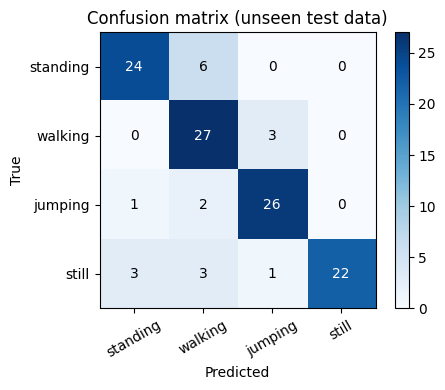

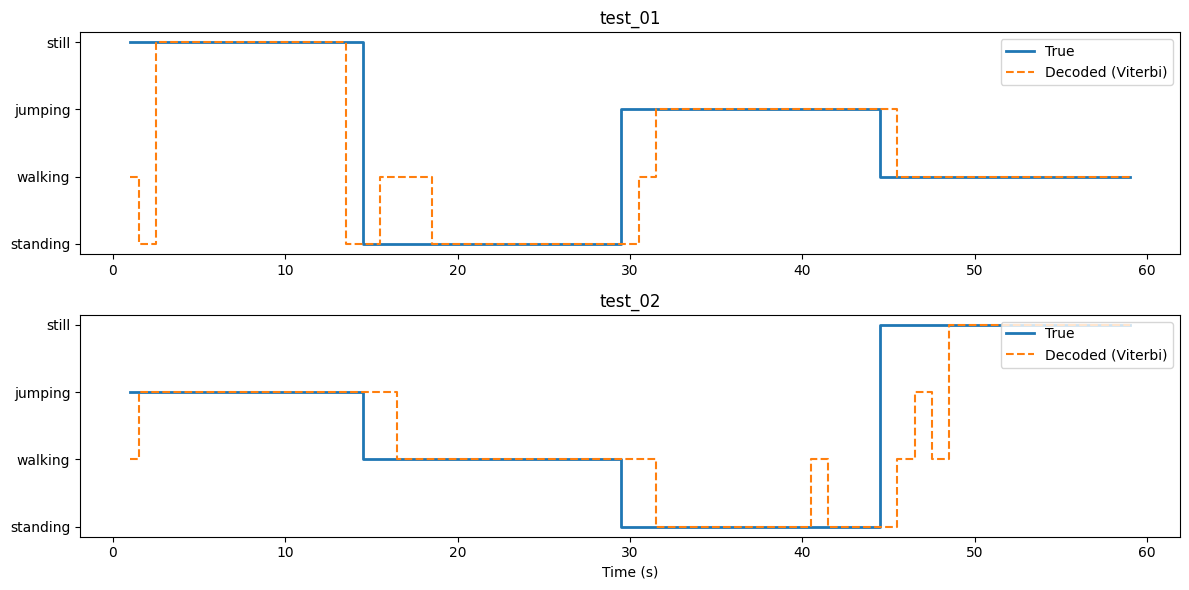

In [ ]:
TEST_SEGMENTS = {
    "test_01": [("still", 0, 15), ("standing", 15, 30), ("jumping", 30, 45), ("walking", 45, 60)],
    "test_02": [("jumping", 0, 15), ("walking", 15, 30), ("standing", 30, 45), ("still", 45, 60)],
}

def true_label_at(name, t):
    for act, s, e in TEST_SEGMENTS[name]:
        if s <= t < e:
            return lab2id[act]
    return None

all_true, all_pred, per_file = [], [], {}
for f in sorted(glob.glob(os.path.join(PROC_DIR, "test", "*.csv"))):
    name = os.path.basename(f).replace(".csv", "")
    if name not in TEST_SEGMENTS:
        print("No segments given for", name, "- skipped"); continue
    df = pd.read_csv(f)
    feats, starts = extract_windows(df)
    tf = transform(pd.DataFrame(feats))
    Xt = ((tf[FEATURE_COLS] - mu) / sd).values
    path, _ = final.viterbi(Xt)
    centers = np.array(starts) + WIN_SEC / 2
    truth = [true_label_at(name, c) for c in centers]
    keep = [i for i, t in enumerate(truth) if t is not None]
    tr = np.array([truth[i] for i in keep]); pr = path[keep]
    all_true += list(tr); all_pred += list(pr)
    per_file[name] = (centers[keep], tr, pr)
    print(f"{name}: {len(keep)} windows, window accuracy = {(tr == pr).mean():.3f}")

if len(per_file) == 0:
    print("\n[WARNING] No test clips processed. Please verify that your test zip files are placed in ZIP_DIR and start with 'test'.")
else:
    all_true, all_pred = np.array(all_true), np.array(all_pred)
    C = np.zeros((4, 4), int)
    for t, p in zip(all_true, all_pred):
        C[t, p] += 1
    N = C.sum()

    rows = []
    for k, a in enumerate(ACTIVITIES):
        TP = C[k, k]; FN = C[k].sum() - TP; FP = C[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({"State (Activity)": a, "Number of Samples": int(C[k].sum()),
                     "Sensitivity": round(TP / (TP + FN), 3) if TP + FN else np.nan,
                     "Specificity": round(TN / (TN + FP), 3) if TN + FP else np.nan,
                     "Accuracy (one-vs-rest)": round((TP + TN) / N, 3)})
    results = pd.DataFrame(rows)
    print("\nTest results:")
    print(results.to_string(index=False))
    print(f"\nOverall accuracy on unseen test data: {np.trace(C) / N:.3f}")
    results.to_csv(f"{FEAT_DIR}/test_results.csv", index=False)

    plt.figure(figsize=(5, 4))
    plt.imshow(C, cmap="Blues")
    for i in range(4):
        for j in range(4):
            plt.text(j, i, C[i, j], ha="center", va="center", color="white" if C[i, j] > C.max() / 2 else "black")
    plt.xticks(range(4), ACTIVITIES, rotation=30); plt.yticks(range(4), ACTIVITIES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (unseen test data)")
    plt.colorbar(); plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/test_confusion_matrix.png", dpi=150); plt.show()

    fig, axes = plt.subplots(len(per_file), 1, figsize=(12, 3 * len(per_file)), squeeze=False)
    for ax, (name, (c, tr, pr)) in zip(axes[:, 0], per_file.items()):
        ax.step(c, tr, where="mid", lw=2, label="True")
        ax.step(c, pr, where="mid", ls="--", label="Decoded (Viterbi)")
        ax.set_yticks(range(4)); ax.set_yticklabels(ACTIVITIES); ax.set_title(name); ax.legend(loc="upper right")
    axes[-1, 0].set_xlabel("Time (s)")
    plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/test_decoded_sequences.png", dpi=150); plt.show()

To Verify: segments labeled on the test signal against the raw test signal

Coloured bands above are the ones entered from the activity segments to verify the labels are aligned with the recorded sensor's haptic activity.


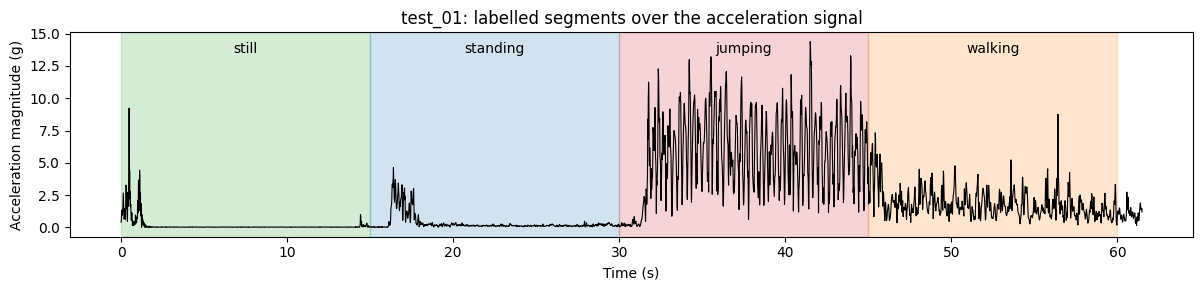

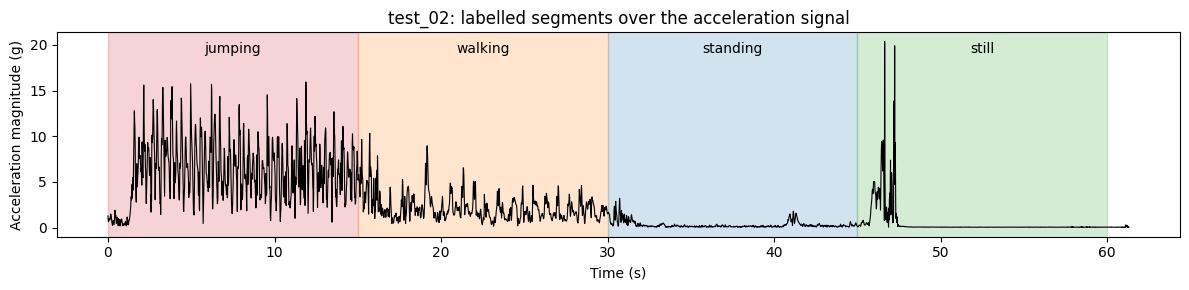

In [ ]:
colors = {"standing": "tab:blue", "walking": "tab:orange", "jumping": "tab:red", "still": "tab:green"}
for f in sorted(glob.glob(os.path.join(PROC_DIR, "test", "*.csv"))):
    name = os.path.basename(f).replace(".csv", "")
    df = pd.read_csv(f)
    m = np.linalg.norm(df[["acc_x", "acc_y", "acc_z"]].values, axis=1)
    plt.figure(figsize=(12, 3))
    plt.plot(df.timestamp, m, lw=0.8, color="black")
    for act, s, e in TEST_SEGMENTS.get(name, []):
        plt.axvspan(s, e, alpha=0.2, color=colors[act])
        plt.text((s + e) / 2, m.max(), act, ha="center", va="top")
    plt.title(f"{name}: labelled segments over the acceleration signal")
    plt.xlabel("Time (s)"); plt.ylabel("Acceleration magnitude (g)")
    plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/{name}_segments.png", dpi=150); plt.show()